**Name** - Harshal Manohar Mekhe<br>
**PRN** - 202401040051<br>
**Roll** - 14<br>
**Subject** - AIML


## Country Development Classification Using Clustering



**Problem Statement:** Implement clustering algorithms on a real-world country development dataset to identify meaningful groups based on socioeconomic and health indicators. Evaluate the quality of clustering results using Silhouette Score, Davies–Bouldin Index, and visual inspection.

## 1. Aim
To analyze country-level socioeconomic and health indicators using **K-Means** and **Agglomerative Hierarchical Clustering**, identify groups of countries with similar characteristics, and compare the quality of the groups using quantitative metrics and plots.

## 2. Objectives
1. Understand unsupervised learning and clustering.
2. Explore and preprocess a real-world country dataset.
3. Apply K-Means and hierarchical clustering on scaled numeric features.
4. Compare candidate numbers of clusters using the elbow curve, silhouette score, and Davies–Bouldin index.
5. Visualize groups with PCA and interpret their socioeconomic characteristics.
6. Discuss limitations of clustering for real-world development decisions.

## 3. Theory

### 3.1 Unsupervised learning and clustering
**Unsupervised learning** finds patterns in data without predefined target labels. **Clustering** groups observations such that observations in a cluster are relatively similar and observations in different clusters are relatively dissimilar. In this experiment, each observation represents a country. The algorithm does not know any official development category in advance.

### 3.2 K-Means clustering
K-Means partitions the data into `k` groups. It starts with `k` centroids, assigns each sample to its nearest centroid, then recomputes centroids until convergence. It aims to minimize within-cluster sum of squares (inertia):

$$J=\sum_{j=1}^{k}\sum_{x_i\in C_j}\|x_i-\mu_j\|^2$$

where $C_j$ is cluster $j$ and $\mu_j$ is its centroid. K-Means works best when groups are reasonably compact in the scaled feature space.

### 3.3 Agglomerative hierarchical clustering
Agglomerative clustering begins with one cluster per country and repeatedly merges the closest clusters. **Ward linkage** chooses merges that minimize the increase in within-cluster variance. A **dendrogram** visualizes the successive merges. Unlike K-Means, this method does not update centroids.

### 3.4 Feature scaling
Income and GDP per capita can be much larger numerically than life expectancy or fertility. Without scaling, distance-based clustering can become dominated by the largest-magnitude indicators. **StandardScaler** transforms a feature to:

$$z=\frac{x-\mu}{\sigma}$$

where $\mu$ is the feature mean and $\sigma$ its standard deviation.

### 3.5 Evaluation metrics
**Silhouette Score** compares mean within-cluster distance $a(i)$ with mean nearest-other-cluster distance $b(i)$:

$$s(i)=\frac{b(i)-a(i)}{\max(a(i), b(i))}$$

Its mean ranges from -1 to 1; **higher is generally better**.

**Davies–Bouldin Index** measures how much clusters overlap using within-cluster scatter compared with distances between cluster centers; **lower is generally better** (minimum 0).

**Inertia** is K-Means' within-cluster sum of squared distances; a lower value alone does not determine the best `k`, because inertia normally falls as `k` increases.

### 3.6 Principal Component Analysis (PCA)
PCA transforms standardized features into orthogonal components. Plotting the first two components provides a **2D visual approximation** of the clusters; it may not preserve all differences in the original nine-dimensional space.

## 4. Dataset and tools
**Dataset:** *Unsupervised Learning on Country Data*, associated with HELP International and publicly hosted on Kaggle. The dataset has **167 countries** and nine numeric socioeconomic/health indicators plus the country name.

| Feature | Meaning |
|---|---|
| `child_mort` | Under-five deaths per 1,000 live births |
| `exports` | Exports as a percentage measure relative to GDP per capita |
| `health` | Health spending as a percentage measure relative to GDP per capita |
| `imports` | Imports as a percentage measure relative to GDP per capita |
| `income` | Net income per person |
| `inflation` | Annual inflation-related measure |
| `life_expec` | Average life expectancy at birth |
| `total_fer` | Average number of births per woman |
| `gdpp` | GDP per person |

**Tools:** Python 3, Google Colab, pandas, NumPy, scikit-learn, SciPy, Matplotlib, seaborn.

**Sources:** [Kaggle dataset](https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data) · [Dataset description](https://search.r-project.org/CRAN/refmans/FPDclustering/html/Country_data.html) · [Public CSV mirror](https://github.com/392781/Country-Clustering-Analysis/blob/master/country-data.csv).

> **Note:** This is a historical educational dataset, not current official country rankings. The derived clusters are patterns in the selected variables, not official country development classifications.

## 5. Procedure and implementation

### Step 1: Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load the real-world dataset
The cell downloads the public CSV from GitHub. If internet access fails, download `Country-data.csv` from the Kaggle link above and use the Colab file-upload prompt.

In [2]:
DATA_URLS = [
    "https://raw.githubusercontent.com/392781/Country-Clustering-Analysis/master/country-data.csv",
    "https://raw.githubusercontent.com/alexkapele/country_clusters/master/Country-data.csv",
]

df = None
for url in DATA_URLS:
    try:
        df = pd.read_csv(url)
        print("Dataset loaded from:", url)
        break
    except Exception as exc:
        print("Source unavailable:", type(exc).__name__)

if df is None:
    from google.colab import files
    print("Upload the Country-data.csv file from Kaggle.")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No dataset uploaded.")
    df = pd.read_csv(next(iter(uploaded)))

required_cols = {"country", "child_mort", "exports", "health", "imports", "income", "inflation", "life_expec", "total_fer", "gdpp"}
if not required_cols.issubset(df.columns):
    raise ValueError(f"Dataset is missing columns: {required_cols - set(df.columns)}")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded from: https://raw.githubusercontent.com/392781/Country-Clustering-Analysis/master/country-data.csv
Dataset shape: (167, 10)


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


### Step 3: Explore data and missing values

In [3]:
print("Data types and missing values:")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
print("Duplicate country names:", df["country"].duplicated().sum())
print("Numerical summary:")
display(df.describe().round(2))

Data types and missing values:


,dtype,missing
country,object,0
child_mort,float64,0
exports,float64,0
health,float64,0
imports,float64,0
income,int64,0
inflation,float64,0
life_expec,float64,0
total_fer,float64,0
gdpp,int64,0


Duplicate country names: 0
Numerical summary:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00
mean,38.27,41.11,6.82,46.89,17144.69,7.78,70.56,2.95,12964.16
std,40.33,27.41,2.75,24.21,19278.07,10.57,8.89,1.51,18328.70
min,2.60,0.11,1.81,0.07,609.00,-4.21,32.10,1.15,231.00
25%,8.25,23.80,4.92,30.20,3355.00,1.81,65.30,1.80,1330.00
50%,19.30,35.00,6.32,43.30,9960.00,5.39,73.10,2.41,4660.00
75%,62.10,51.35,8.60,58.75,22800.00,10.75,76.80,3.88,14050.00
max,208.00,200.00,17.90,174.00,125000.00,104.00,82.80,7.49,105000.00


### Step 4: Preprocess and standardize
We exclude the text country names from modeling, convert the indicator columns to numeric, fill any missing values with each column median, and standardize all numeric features. Country names remain available for reporting.

In [4]:
features = ["child_mort", "exports", "health", "imports", "income",
            "inflation", "life_expec", "total_fer", "gdpp"]
X = df[features].apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature matrix shape:", X_scaled.shape)
print("Approximate means:", np.round(X_scaled.mean(axis=0), 3))
print("Approximate stds:", np.round(X_scaled.std(axis=0), 3))

Feature matrix shape: (167, 9)
Approximate means: [-0.  0.  0.  0. -0. -0.  0.  0.  0.]
Approximate stds: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Step 5: Explore relationships between important indicators

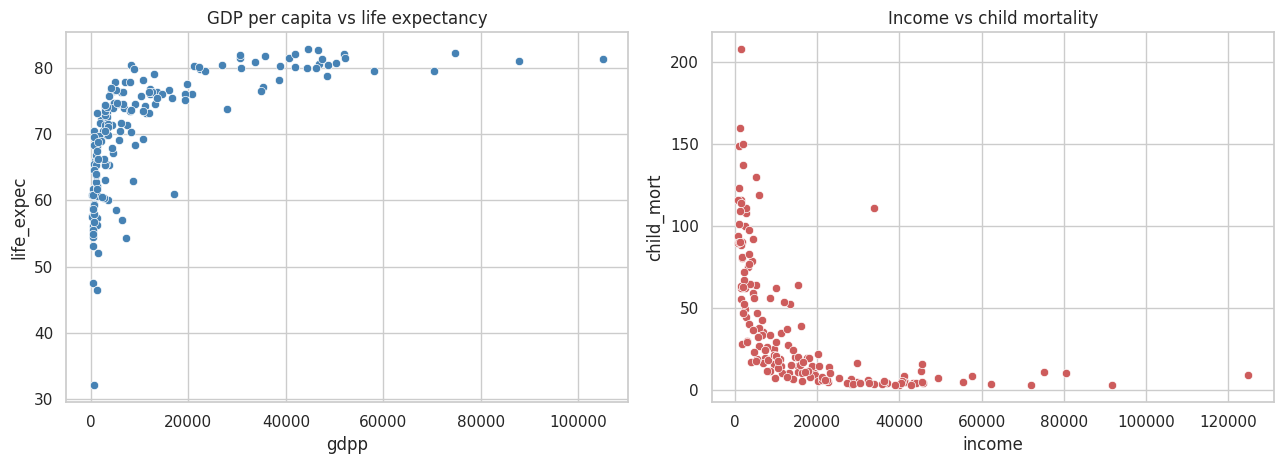

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=df, x="gdpp", y="life_expec", ax=axes[0], color="steelblue")
axes[0].set_title("GDP per capita vs life expectancy")
sns.scatterplot(data=df, x="income", y="child_mort", ax=axes[1], color="indianred")
axes[1].set_title("Income vs child mortality")
plt.tight_layout()
plt.show()

### Step 6: Choose cluster count
We evaluate **k = 2 to 8** on the same standardized data. The best silhouette candidate is selected separately for each algorithm, while the Davies–Bouldin score and interpretability are used to assess the choice. We also inspect the K-Means elbow curve.

,Algorithm,k,Silhouette,Davies-Bouldin,Inertia
0,K-Means,2,0.287,1.304,1050.215
1,Hierarchical (Ward),2,0.315,1.327,NaN
2,K-Means,3,0.283,1.277,831.424
3,Hierarchical (Ward),3,0.246,1.300,NaN
4,K-Means,4,0.296,1.053,700.521
5,Hierarchical (Ward),4,0.248,1.080,NaN
6,K-Means,5,0.299,0.872,620.163
7,Hierarchical (Ward),5,0.219,1.301,NaN
8,K-Means,6,0.229,1.078,558.470
9,Hierarchical (Ward),6,0.218,1.113,NaN


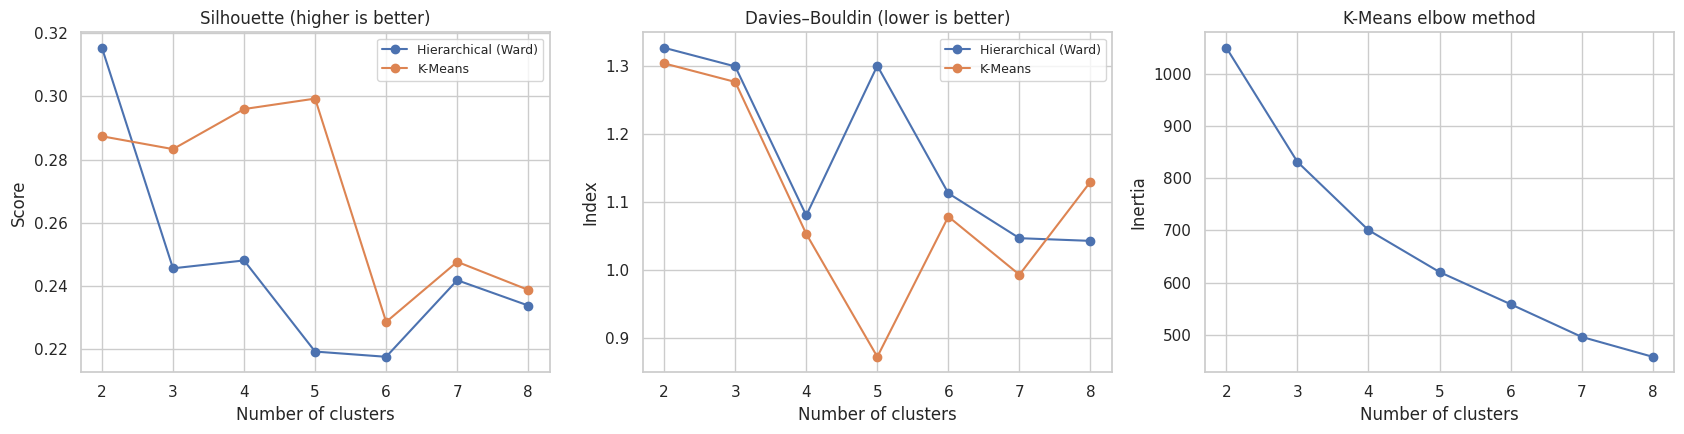

In [6]:
k_values = range(2, 9)
rows = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km_labels = km.fit_predict(X_scaled)
    rows.append({"Algorithm": "K-Means", "k": k,
                 "Silhouette": silhouette_score(X_scaled, km_labels),
                 "Davies-Bouldin": davies_bouldin_score(X_scaled, km_labels),
                 "Inertia": km.inertia_})
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward")
    hc_labels = hc.fit_predict(X_scaled)
    rows.append({"Algorithm": "Hierarchical (Ward)", "k": k,
                 "Silhouette": silhouette_score(X_scaled, hc_labels),
                 "Davies-Bouldin": davies_bouldin_score(X_scaled, hc_labels),
                 "Inertia": np.nan})
metrics = pd.DataFrame(rows)
display(metrics.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for algo, part in metrics.groupby("Algorithm"):
    axes[0].plot(part["k"], part["Silhouette"], marker="o", label=algo)
    axes[1].plot(part["k"], part["Davies-Bouldin"], marker="o", label=algo)
axes[2].plot(metrics.loc[metrics["Algorithm"] == "K-Means", "k"],
             metrics.loc[metrics["Algorithm"] == "K-Means", "Inertia"], marker="o")
axes[0].set(title="Silhouette (higher is better)", xlabel="Number of clusters", ylabel="Score")
axes[1].set(title="Davies–Bouldin (lower is better)", xlabel="Number of clusters", ylabel="Index")
axes[2].set(title="K-Means elbow method", xlabel="Number of clusters", ylabel="Inertia")
axes[0].legend(fontsize=9)
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

### Step 7: Train the final clustering models
For a reproducible automated comparison, select the `k` with the highest silhouette score *within each algorithm*. The two models may therefore choose different cluster counts. Later, interpret their profiles to judge usefulness.

In [7]:
best_k_kmeans = int(metrics.loc[metrics["Algorithm"] == "K-Means"]
                    .sort_values("Silhouette", ascending=False).iloc[0]["k"])
best_k_hier = int(metrics.loc[metrics["Algorithm"] == "Hierarchical (Ward)"]
                  .sort_values("Silhouette", ascending=False).iloc[0]["k"])

kmeans = KMeans(n_clusters=best_k_kmeans, random_state=RANDOM_STATE, n_init=10)
hierarchical = AgglomerativeClustering(n_clusters=best_k_hier, linkage="ward")
km_labels = kmeans.fit_predict(X_scaled)
hc_labels = hierarchical.fit_predict(X_scaled)

result = df.copy()
result["KMeans_Cluster"] = km_labels
result["Hierarchical_Cluster"] = hc_labels
print(f"Selected K-Means k = {best_k_kmeans}; Hierarchical k = {best_k_hier}")
display(result[["country", "KMeans_Cluster", "Hierarchical_Cluster"]].head(12))

Selected K-Means k = 5; Hierarchical k = 2


,country,KMeans_Cluster,Hierarchical_Cluster
0,Afghanistan,1,0
1,Albania,0,0
2,Algeria,0,0
3,Angola,1,0
4,Antigua and Barbuda,0,0
5,Argentina,0,0
6,Armenia,0,0
7,Australia,3,1
8,Austria,3,1
9,Azerbaijan,0,0


### Step 8: Compare final model scores

In [8]:
comparison = pd.DataFrame([
    {"Algorithm": "K-Means", "Clusters": best_k_kmeans,
     "Silhouette Score": silhouette_score(X_scaled, km_labels),
     "Davies-Bouldin Index": davies_bouldin_score(X_scaled, km_labels)},
    {"Algorithm": "Hierarchical (Ward)", "Clusters": best_k_hier,
     "Silhouette Score": silhouette_score(X_scaled, hc_labels),
     "Davies-Bouldin Index": davies_bouldin_score(X_scaled, hc_labels)}
])
display(comparison.round(3))
print("Best silhouette:", comparison.loc[comparison["Silhouette Score"].idxmax(), "Algorithm"])
print("Best Davies–Bouldin:", comparison.loc[comparison["Davies-Bouldin Index"].idxmin(), "Algorithm"])
print("Note: score winners can differ. No metric alone guarantees meaningful development groups.")

,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index
0,K-Means,5,0.299,0.872
1,Hierarchical (Ward),2,0.315,1.327


Best silhouette: Hierarchical (Ward)
Best Davies–Bouldin: K-Means
Note: score winners can differ. No metric alone guarantees meaningful development groups.


### Step 9: Visualize clusters with PCA
The clustering above uses all nine scaled features. PCA is used *only for 2D visualization*, not as the input to the clustering algorithms.

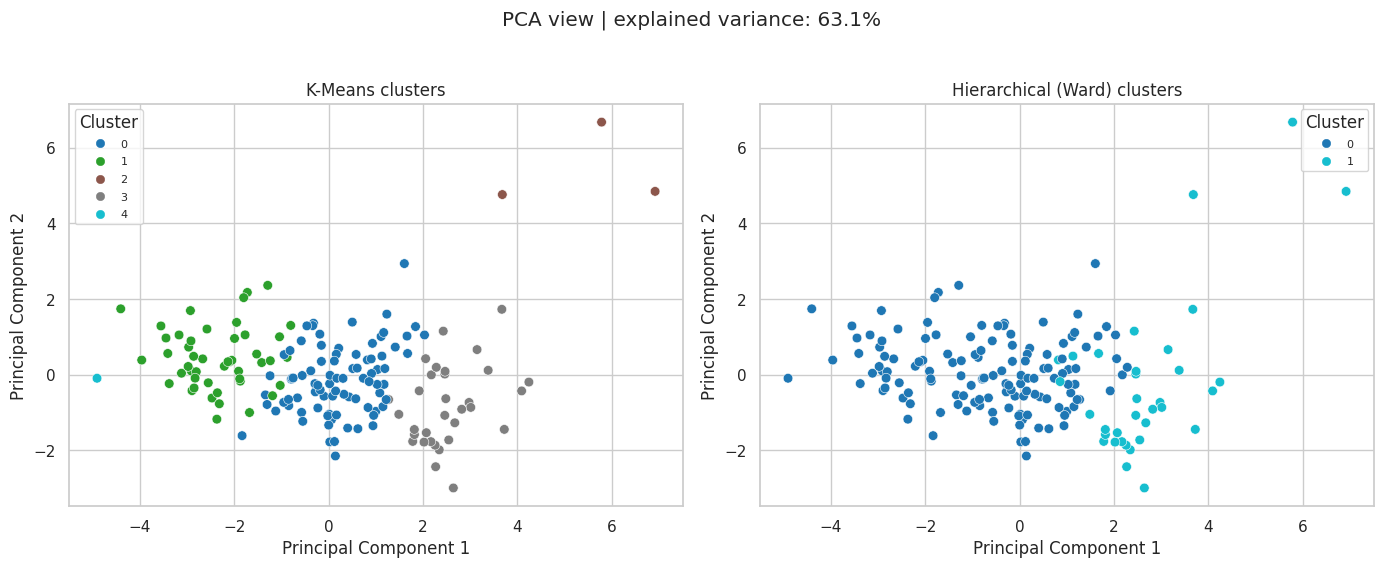

In [9]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, labels, title in zip(axes, [km_labels, hc_labels],
                             ["K-Means clusters", "Hierarchical (Ward) clusters"]):
    scatter = ax.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="tab10",
                         s=48, edgecolors="white", linewidths=0.4)
    ax.set(title=title, xlabel="Principal Component 1", ylabel="Principal Component 2")
    ax.legend(*scatter.legend_elements(), title="Cluster", loc="best", fontsize=8)
plt.suptitle(f"PCA view | explained variance: {sum(pca.explained_variance_ratio_):.1%}", y=1.03)
plt.tight_layout()
plt.show()

### Step 10: Hierarchical dendrogram
The dendrogram shows how countries merge according to Ward linkage. Because there are 167 observations, the displayed tree is truncated to its final merges to improve readability.

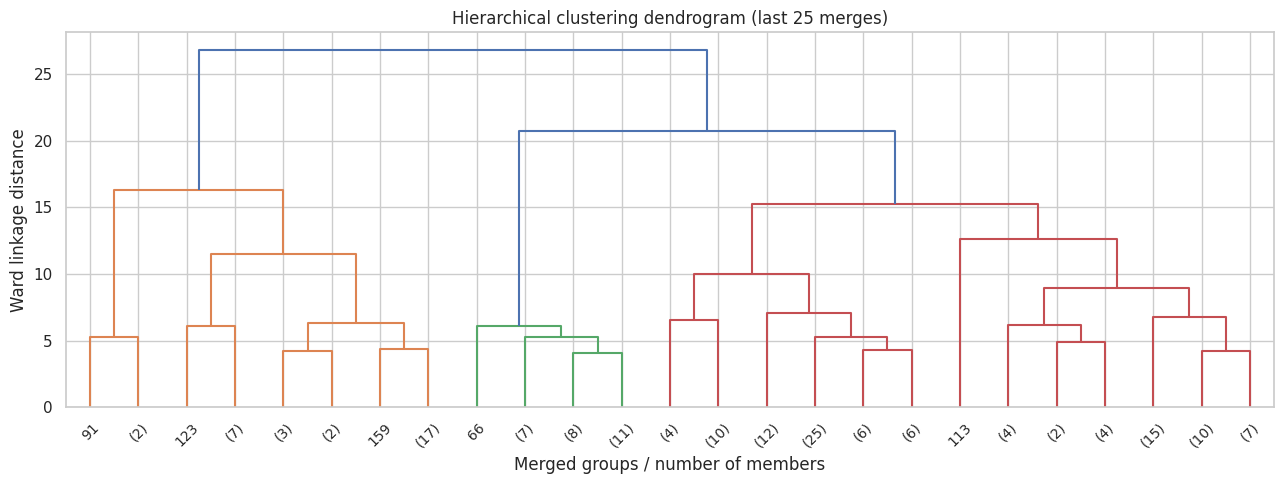

In [10]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=25, show_leaf_counts=True, leaf_rotation=45)
plt.title("Hierarchical clustering dendrogram (last 25 merges)")
plt.xlabel("Merged groups / number of members")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

### Step 11: Interpret meaningful country groups
Cluster numbers are arbitrary identifiers, **not ordered development ranks**. Examine the mean income, GDP, child mortality, life expectancy, and fertility for each cluster before assigning any descriptive label. Means are sensitive to extreme values, so the medians can also be useful.

In [11]:
profile_features = ["income", "gdpp", "child_mort", "life_expec", "total_fer"]
for column, name in [("KMeans_Cluster", "K-Means"),
                     ("Hierarchical_Cluster", "Hierarchical")]:
    print(f"\n{name} cluster sizes:")
    display(result[column].value_counts().sort_index().rename("Countries").to_frame())
    print(f"{name} cluster mean profiles:")
    display(result.groupby(column)[profile_features].mean().round(2))
    print(f"{name} example countries (up to 8 per cluster):")
    for cluster_id, part in result.groupby(column):
        print(f"  Cluster {cluster_id}: {', '.join(part['country'].head(8).astype(str))}")


K-Means cluster sizes:


,Countries
KMeans_Cluster,
0,84
1,47
2,3
3,32
4,1


K-Means cluster mean profiles:


,income,gdpp,child_mort,life_expec,total_fer
KMeans_Cluster,,,,,
0,12801.07,6581.81,21.61,73.00,2.28
1,3870.70,1900.26,90.79,59.21,4.97
2,64033.33,57566.67,4.13,81.43,1.38
3,44021.88,42118.75,5.18,80.08,1.79
4,5150.00,2330.00,130.00,60.50,5.84


K-Means example countries (up to 8 per cluster):
  Cluster 0: Albania, Algeria, Antigua and Barbuda, Argentina, Armenia, Azerbaijan, Bahrain, Bangladesh
  Cluster 1: Afghanistan, Angola, Benin, Botswana, Burkina Faso, Burundi, Cameroon, Central African Republic
  Cluster 2: Luxembourg, Malta, Singapore
  Cluster 3: Australia, Austria, Bahamas, Belgium, Brunei, Canada, Cyprus, Czech Republic
  Cluster 4: Nigeria

Hierarchical cluster sizes:


,Countries
Hierarchical_Cluster,
0,133
1,34


Hierarchical cluster mean profiles:


,income,gdpp,child_mort,life_expec,total_fer
Hierarchical_Cluster,,,,,
0,9362.13,5242.21,46.53,68.15,3.22
1,47588.24,43170.59,5.96,79.98,1.89


Hierarchical example countries (up to 8 per cluster):
  Cluster 0: Afghanistan, Albania, Algeria, Angola, Antigua and Barbuda, Argentina, Armenia, Azerbaijan
  Cluster 1: Australia, Austria, Bahrain, Belgium, Brunei, Canada, Denmark, Finland


### Step 12: Visual comparison of socioeconomic profiles

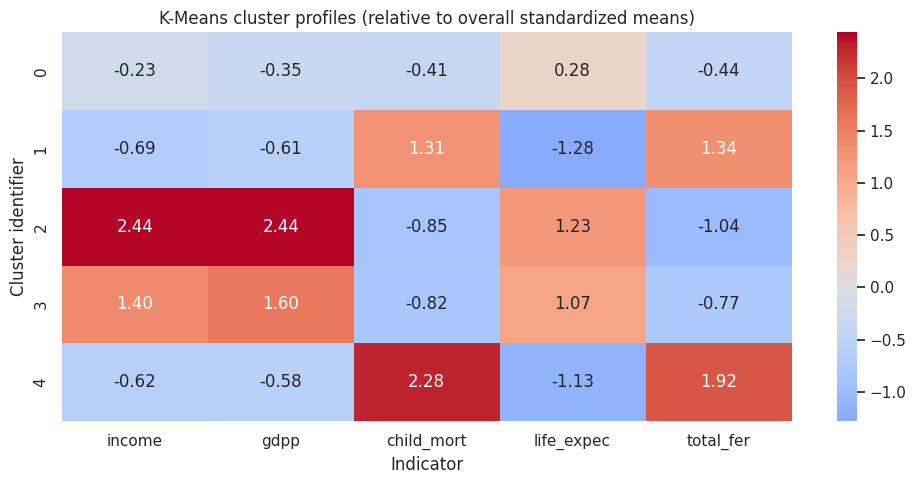

Positive = above dataset average; negative = below dataset average.


In [12]:
cluster_profiles = result.groupby("KMeans_Cluster")[profile_features].mean()
normalized_profiles = (cluster_profiles - X[profile_features].mean()) / X[profile_features].std(ddof=0)
plt.figure(figsize=(10, max(3, 1.0 * len(cluster_profiles))))
sns.heatmap(normalized_profiles, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("K-Means cluster profiles (relative to overall standardized means)")
plt.xlabel("Indicator")
plt.ylabel("Cluster identifier")
plt.tight_layout()
plt.show()
print("Positive = above dataset average; negative = below dataset average.")

### Step 13: Export results for submission

In [13]:
output_name = "country_development_clustering_results.csv"
result.to_csv(output_name, index=False)
print("Saved:", output_name)
display(result.head())
# Optional in Colab: uncomment the next two lines to download to your computer.
# from google.colab import files
# files.download(output_name)

Saved: country_development_clustering_results.csv


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,KMeans_Cluster,Hierarchical_Cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,1,0
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,0,0
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,0,0
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,1,0
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,0,0


## 7. Conclusion
This experiment demonstrates how unsupervised machine learning can organize countries into groups that share similar socioeconomic and health characteristics. K-Means and Agglomerative Hierarchical Clustering were applied to standardized features, and their solutions were evaluated using Silhouette Score, Davies–Bouldin Index, and PCA-based visual inspection. The resulting cluster profiles can reveal different development-related patterns, but they are **not official country labels** and should not be used alone to determine aid eligibility or public policy.

**After execution, personalize this conclusion:** The better-performing model according to the evaluation was **[algorithm]**, with Silhouette Score **[value]** and Davies–Bouldin Index **[value]**. The most notable country-group differences were **[briefly state patterns from the profile table]**.

## 8. Learning outcomes
- Learned the distinction between supervised and unsupervised learning.
- Implemented K-Means and Agglomerative Hierarchical Clustering in Python.
- Performed numeric preprocessing and standardization.
- Evaluated clusters with two complementary metrics.
- Used PCA, a dendrogram, and cluster profiles for interpretation.
- Understood why clustering patterns must be interpreted carefully in real-world policy contexts.

## 9. References
1. Kaggle — *Unsupervised Learning on Country Data*: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data
2. Public CSV mirror — https://github.com/392781/Country-Clustering-Analysis/blob/master/country-data.csv
3. CRAN dataset documentation — https://search.r-project.org/CRAN/refmans/FPDclustering/html/Country_data.html
4. Scikit-learn — K-Means: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
5. Scikit-learn — Clustering performance evaluation: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation